<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/code/04-data-stochastic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!curl -l -o data.csv https://raw.githubusercontent.com/tlh222k/aio/refs/heads/main/data/data.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100    31  100    31    0     0    162      0 --:--:-- --:--:-- --:--:--   163


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
data = np.genfromtxt("/content/data.csv",delimiter=",")
data

array([[6.7, 9.1],
       [4.6, 5.9],
       [3.5, 4.6],
       [5.5, 6.7]])

N: 4
areas: [6.7 4.6 3.5 5.5]
prices: [9.1 5.9 4.6 6.7]


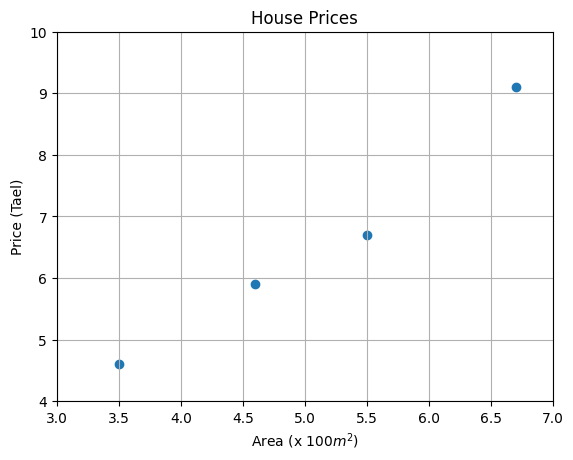

In [ ]:
areas = data[:,0]
prices = data[:,-1]
N = data.shape[0]

print(f"N: {N}")
print(f"areas: {areas}")
print(f"prices: {prices}")

plt.scatter(areas, prices)
plt.xlabel("Area (x 100$m^2$)")
plt.xlim(3,7)
plt.ylabel("Price (Tael)")
plt.ylim(4,10)
plt.title("House Prices")
plt.grid(True)
plt.show()

In [ ]:
def predict(x, w, b):
  return x*w + b

def gradient(y, y_hat, x):
  dw = 2*x*(y_hat - y)
  db = 2*(y_hat - y)
  return dw, db

def update_weight(w, b, dw, db, lr):
  w -= lr * dw
  b -= lr * db
  return w, b



In [ ]:
def forward_propagation(x, w, b):
  y_hat = predict(x, w, b)
  return y_hat

def back_propagation(x, y,y_hat):
  dw, db = gradient(y, y_hat, x)
  return dw, db

In [ ]:
# init weights
b = 0.04
w = -0.34
lr = 0.02

# parameter
epoch_max = 10
losses = []

for epoch in range(epoch_max):

  for i in range(N):
    x = areas[i]
    y = prices[i]

    y_hat = forward_propagation(x, w, b)

    loss = (y_hat - y)**2
    losses.append(loss)

    dw, db = back_propagation(x, y, y_hat)

    w, b = update_weight(w, b, dw, db, lr)

print(f"w: {w}")
print(f"b: {b}")

w: 1.192491163985917
b: 0.017371370027855694


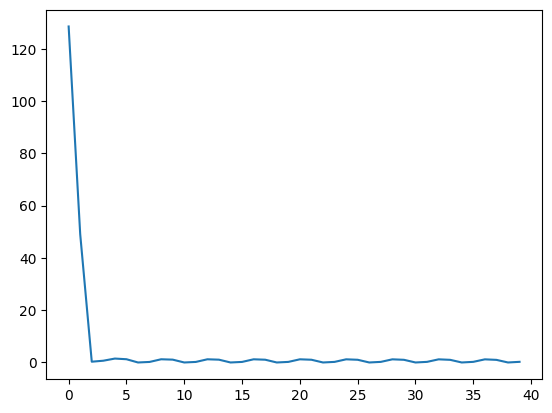

In [ ]:
import matplotlib.pyplot as plt
plt.plot(losses)

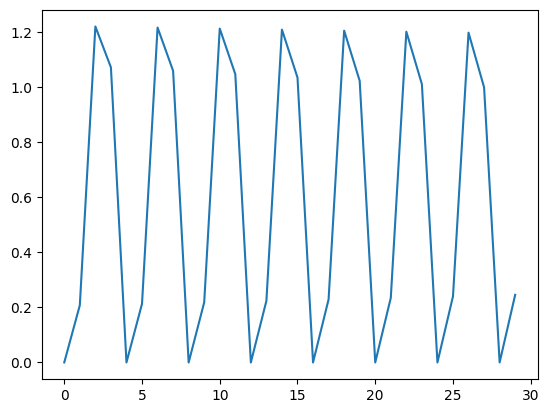

In [ ]:
import matplotlib.pyplot as plt
plt.plot(losses[10:])


In [ ]:
area_real = 6
predicted_price = area_real*w + b
print('predicted_price: ', predicted_price)

predicted_price:  7.172318353943358


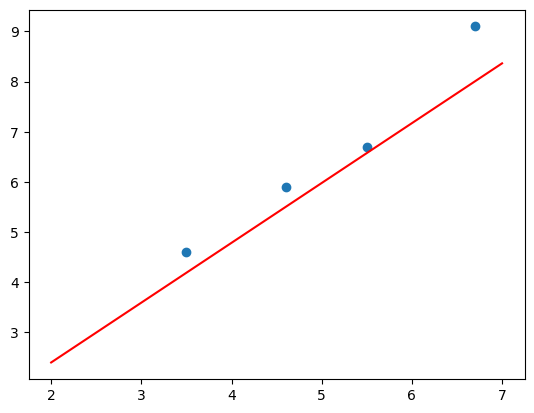

In [ ]:
x_data = range(2, 8)
y_data = [x*w + b for x in x_data]
plt.plot(x_data, y_data, 'r')

plt.scatter(areas, prices)
